# Build Parcel Adjacency Matrices from Wang432 Volumetric Atlases

This notebook builds spatial adjacency matrices for each age's Wang432 parcellation, ready for use in TFCE-based analysis. The pipeline:

1. Load the per-age registered Wang432 NIfTI (the same file the MATLAB pipeline reads as `maskParc`).
2. Dilate each parcel label outward to fill the cortical volume — mirroring the MATLAB `strel('sphere', 3)` step but with an atlas-space-appropriate radius.
3. Build adjacency from the dilated volume — two parcels are neighbours if they share at least `min_contact_voxels` of voxel-face contact.
4. Run sanity checks (neighbour counts, isolated parcels, hemisphere structure).
5. Diagnose alignment between adjacency parcel IDs and data parcel IDs (`metadataDf['Parcel']`).
6. Save adjacency + parcel order to disk for reuse in the TFCE analysis.


## 1. Imports and configuration

In [13]:
from pathlib import Path
import pickle

import nibabel as nib
import numpy as np
import pandas as pd
from scipy import ndimage

import time

In [ ]:
# ---- Paths to the per-age registered Wang432 atlas NIfTIs ----
# Same files that the MATLAB pipeline loads as `maskParc`.
ATLAS_BASE = Path("/Path/to/NIFTI/files/containing/volumetric/projection/of/surface/parcellation")

ATLAS_FILES = {
    1:  ATLAS_BASE / "01mo" / "01mo_WangFunctional_Reg_Head.nii.gz",
    6:  ATLAS_BASE / "06mo" / "06mo_WangFunctional_Reg_Head.nii.gz",
    12: ATLAS_BASE / "12mo" / "12mo_WangFunctional_Reg_Head.nii.gz",
}

# Where to save the resulting adjacency matrices
OUTPUT_DIR = Path("/Path/to/output/adjacencyMatrices")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Path to  metadata CSV/parquet for the alignment check
METADATA_PATH = Path("/Path/to/metadata/file/created/with/getParcelTrialsDataframe.csv")

# ---- Wang432 atlas conventions ----
# LH parcels: integer IDs 1..430
# RH parcels: integer IDs 431..862
# (matches the MATLAB script's hemisphere convention)
LH_ID_MIN, LH_ID_MAX = 1, 430
RH_ID_MIN, RH_ID_MAX = 431, 862

# ---- Dilation parameters ----
# MATLAB does strel('sphere', 3) in DOT space at 2mm isotropic voxels — that's
# 6mm physical radius. The atlas NIfTIs are 1mm isotropic, so to match the same
# physical extent we use radius 6 voxels here.
DILATION_RADIUS_VOXELS = 3   # at 1mm isotropic = 6mm physical

# ---- Adjacency parameters ----
# Minimum number of shared shell voxels for two parcels to be flagged as neighbours.
# Higher values filter out spurious single-voxel sulcal-bank contacts. Tune
# empirically based on the neighbour-count distribution.
# Note: at 1mm voxels, 12 voxels of contact = 12 mm² of physical contact area,
# roughly equivalent to 3 voxels at the 2mm DOT resolution.
MIN_CONTACT_VOXELS = 12

# Connectivity for adjacency check: 1 = 6-connectivity (faces only), 3 = 26-connectivity
# 6-connectivity is more conservative and avoids spurious diagonal contacts.
ADJACENCY_CONNECTIVITY = 1

## 2. Core functions: load, dilate, build adjacency

In [15]:
def load_wang432_atlas(nifti_path):
    """
    Load a Wang432 atlas NIfTI and return integer-typed labels.
    
    The file should already be integer-valued (each voxel = a parcel ID).
    We round and cast to int32 defensively in case there's any float
    representation in the NIfTI header.
    """
    img = nib.load(str(nifti_path))
    data = img.get_fdata()
    parcellation = np.rint(data).astype(np.int32)
    
    # Quick header info
    voxel_size = img.header.get_zooms()
    
    return parcellation, voxel_size, img


def make_sphere_struct(radius):
    """
    Build a 3D spherical structuring element of the given voxel radius,
    matching MATLAB's `strel('sphere', radius)` reasonably closely.
    
    Returns a boolean array of shape (2*radius+1, 2*radius+1, 2*radius+1)
    where True indicates voxels within the sphere.
    """
    diameter = 2 * radius + 1
    centre = radius
    struct = np.zeros((diameter, diameter, diameter), dtype=bool)
    for x in range(diameter):
        for y in range(diameter):
            for z in range(diameter):
                if (x - centre)**2 + (y - centre)**2 + (z - centre)**2 <= radius**2:
                    struct[x, y, z] = True
    return struct

def dilate_per_label(parcellation, struct_radius=6, verbose=True):
    """
    Per-label dilation that preserves all original voxels.
    For each parcel, compute its binary dilation by a sphere of the given
    radius.
    
    Each label can only claim background voxels (== 0); it cannot
    overwrite another parcel's original territory. This guarantees no parcel 
    disappears during dilation.

    Parameters
    ----------
    parcellation : ndarray, dtype int
        Volumetric labelmap. 0 = background.
    struct_radius : int
        Sphere radius in voxels. At 1mm voxels, set to 6 to match the
        MATLAB pipeline's 6mm physical dilation.
    verbose : bool
        Print per-label progress every 50 labels.
    
    Returns
    -------
    dilated : ndarray, dtype int32
        Same shape as input. Each voxel labelled with the parcel ID it
        was claimed by, or 0 if not claimed by any dilation.
    """
    unique_labels = sorted(np.unique(parcellation[parcellation > 0]).tolist())
    n_labels = len(unique_labels)
    
    # Start with the original parcellation in place — all parcels protected
    dilated = parcellation.copy().astype(np.int32)
    struct = make_sphere_struct(struct_radius)
    
    if verbose:
        print(f"    Dilating {n_labels} labels with sphere radius {struct_radius}...")
    
    for i, lbl in enumerate(unique_labels):
        bin_mask = (parcellation == lbl)
        dilated_bin = ndimage.binary_dilation(bin_mask, structure=struct)
        # Only claim voxels that are currently background
        new_vox = dilated_bin & (dilated == 0)
        dilated[new_vox] = lbl
        
        if verbose and (i + 1) % 50 == 0:
            print(f"      {i + 1}/{n_labels} labels processed")
    
    return dilated

def adjacency_from_dilated_volume(dilated, min_contact_voxels=12, connectivity=1,
                                   verbose=True):
    """
    Build parcel adjacency from a dilated volumetric labelmap.
    
    Two parcels are neighbours if their voxel territories share at least
    `min_contact_voxels` of contact in the dilated volume.
    
    Parameters
    ----------
    dilated : ndarray, dtype int
        Dilated parcellation volume.
    min_contact_voxels : int
        Minimum voxels of shared contact for adjacency.
    connectivity : int
        1 = 6-connectivity (faces); 3 = 26-connectivity (faces + edges + corners).
    
    Returns
    -------
    adjacency : ndarray, shape (n_parcels, n_parcels), dtype bool
    parcel_ids : list of int
        Sorted parcel IDs in adjacency-matrix order.
    """
    parcel_ids = sorted(np.unique(dilated[dilated > 0]).tolist())
    n = len(parcel_ids)
    id_to_idx = {pid: i for i, pid in enumerate(parcel_ids)}
    
    adjacency = np.zeros((n, n), dtype=bool)
    struct = ndimage.generate_binary_structure(3, connectivity)
    
    if verbose:
        print(f"    Building adjacency from {n} parcels (min_contact={min_contact_voxels})...")
    
    for i, pid in enumerate(parcel_ids):
        mask = (dilated == pid)
        # Dilate by one voxel — the new shell shows what touches this parcel
        shell = ndimage.binary_dilation(mask, structure=struct) & ~mask
        neighbour_ids, counts = np.unique(dilated[shell], return_counts=True)
        
        idx_i = id_to_idx[pid]
        for nid, count in zip(neighbour_ids, counts):
            if nid == 0 or nid not in id_to_idx:
                continue
            if count < min_contact_voxels:
                continue
            idx_j = id_to_idx[nid]
            adjacency[idx_i, idx_j] = True
            adjacency[idx_j, idx_i] = True
        
        if verbose and (i + 1) % 100 == 0:
            print(f"      {i + 1}/{n} parcels processed")
    
    return adjacency, parcel_ids

## 3. Build adjacency for each age

Slow step: 1mm voxels with a radius-6 dilation, = roughly 1–3 minutes per age depending on label count and image size. Dilation is the main cost; the subsequent adjacency build is faster.

In [16]:


adjacencies = {}        # age -> (adjacency, parcel_order)
dilated_volumes = {}    # age -> dilated volume (kept for sanity-check visualisations)
voxel_sizes = {}        # age -> voxel zooms

for age, atlas_path in ATLAS_FILES.items():
    print(f"\n--- Building adjacency for age {age} ---")
    
    if not Path(atlas_path).exists():
        print(f"  SKIPPED — atlas file not found: {atlas_path}")
        continue
    
    t0 = time.time()
    
    # Load the atlas
    parcellation, voxel_size, img = load_wang432_atlas(atlas_path)
    voxel_sizes[age] = voxel_size
    print(f"  Loaded atlas: shape {parcellation.shape}, voxel size {voxel_size}")
    
    n_voxels_pre = (parcellation > 0).sum()
    print(f"  Nonzero voxels (pre-dilation): {n_voxels_pre:,}")
    print(f"  Unique parcels (pre-dilation): {len(np.unique(parcellation[parcellation > 0]))}")
    
    # Dilate
    dilated = dilate_per_label(parcellation, struct_radius=DILATION_RADIUS_VOXELS, verbose=True)
    n_voxels_post = (dilated > 0).sum()
    expansion = n_voxels_post / max(n_voxels_pre, 1)
    print(f"  Nonzero voxels (post-dilation): {n_voxels_post:,} (×{expansion:.2f})")
    
    dilated_volumes[age] = dilated
    
    # Build adjacency
    adj, order = adjacency_from_dilated_volume(
        dilated,
        min_contact_voxels=MIN_CONTACT_VOXELS,
        connectivity=ADJACENCY_CONNECTIVITY,
        verbose=True,
    )
    
    adjacencies[age] = (adj, order)
    elapsed = time.time() - t0
    print(f"  Built adjacency: {adj.shape[0]} parcels, {adj.sum() // 2} edges. "
          f"({elapsed:.1f}s)")


--- Building adjacency for age 1 ---
  Loaded atlas: shape (127, 160, 155), voxel size (1.0, 1.0, 1.0)
  Nonzero voxels (pre-dilation): 33,953
  Unique parcels (pre-dilation): 860
    Dilating 860 labels with sphere radius 3...
      50/860 labels processed
      100/860 labels processed
      150/860 labels processed
      200/860 labels processed
      250/860 labels processed
      300/860 labels processed
      350/860 labels processed
      400/860 labels processed
      450/860 labels processed
      500/860 labels processed
      550/860 labels processed
      600/860 labels processed
      650/860 labels processed
      700/860 labels processed
      750/860 labels processed
      800/860 labels processed
      850/860 labels processed
  Nonzero voxels (post-dilation): 281,805 (×8.30)
    Building adjacency from 860 parcels (min_contact=12)...
      100/860 parcels processed
      200/860 parcels processed
      300/860 parcels processed
      400/860 parcels processed
      5

## 4. Sanity checks on the adjacency matrices

Things worth seeing:

- **Mean neighbour count**: typically 5–10 for surface parcellations after volumetric dilation. Much higher than that suggests `MIN_CONTACT_VOXELS` is too low (sulcal bridging); much lower suggests it's too high.
- **Min**: 0 means there are isolated parcels. A small handful is normal but many is problematic -> consider regenerating.
- **Hemisphere structure**: LH and RH parcel IDs should be in their expected ranges (1–430 and 431–862), and there should be very few cross-hemisphere edges (any cross-hemisphere edges would be from parcels physically close in 3D space across the medial wall after dilation — possible but should be rare).

In [17]:
def adjacency_sanity_check(adj, parcel_order):
    """Print summary stats and structural checks for one adjacency matrix."""
    n = adj.shape[0]
    neighbour_counts = adj.sum(axis=1)
    
    print(f"  Parcels: {n}")
    print(f"  Edges (undirected): {adj.sum() // 2}")
    print(f"  Mean neighbours: {neighbour_counts.mean():.2f}")
    print(f"  Median neighbours: {np.median(neighbour_counts):.0f}")
    print(f"  Min / max neighbours: {neighbour_counts.min()} / {neighbour_counts.max()}")
    
    # Structural checks
    is_symmetric = np.array_equal(adj, adj.T)
    has_self_loops = bool(np.any(np.diag(adj)))
    print(f"  Symmetric: {is_symmetric}")
    print(f"  Self-loops (should be False): {has_self_loops}")
    
    # Isolated parcels
    isolated_idx = np.where(neighbour_counts == 0)[0]
    if len(isolated_idx) > 0:
        print(f"  Isolated parcels ({len(isolated_idx)}):")
        isolated_ids = [parcel_order[i] for i in isolated_idx]
        # Show first 10
        for pid in isolated_ids[:10]:
            print(f"    parcel ID {pid}")
        if len(isolated_ids) > 10:
            print(f"    ... and {len(isolated_ids) - 10} more")
    else:
        print(f"  Isolated parcels: 0")
    
    # Hemisphere structure
    lh_idx = [i for i, pid in enumerate(parcel_order) if LH_ID_MIN <= pid <= LH_ID_MAX]
    rh_idx = [i for i, pid in enumerate(parcel_order) if RH_ID_MIN <= pid <= RH_ID_MAX]
    other_idx = [i for i, pid in enumerate(parcel_order) 
                 if not (LH_ID_MIN <= pid <= LH_ID_MAX) 
                 and not (RH_ID_MIN <= pid <= RH_ID_MAX)]
    
    print(f"  LH parcels (IDs {LH_ID_MIN}–{LH_ID_MAX}): {len(lh_idx)}")
    print(f"  RH parcels (IDs {RH_ID_MIN}–{RH_ID_MAX}): {len(rh_idx)}")
    if other_idx:
        print(f"  WARNING: parcels with IDs outside expected ranges: {len(other_idx)}")
        for i in other_idx[:5]:
            print(f"    parcel ID {parcel_order[i]}")
    
    if lh_idx and rh_idx:
        cross_edges = adj[np.ix_(lh_idx, rh_idx)].sum()
        print(f"  Cross-hemisphere edges: {cross_edges}")
    
    # Distribution of neighbour counts
    bins = [0, 1, 3, 6, 10, 15, 25, 1000]
    hist, _ = np.histogram(neighbour_counts, bins=bins)
    print(f"  Neighbour count distribution:")
    for lo, hi, count in zip(bins[:-1], bins[1:], hist):
        if count > 0:
            print(f"    [{lo:>4}, {hi:>4}): {count:>4} parcels")


for age, (adj, order) in adjacencies.items():
    print(f"\n=== Age {age}mo ===")
    adjacency_sanity_check(adj, order)


=== Age 1mo ===
  Parcels: 860
  Edges (undirected): 2769
  Mean neighbours: 6.44
  Median neighbours: 6
  Min / max neighbours: 1 / 15
  Symmetric: True
  Self-loops (should be False): False
  Isolated parcels: 0
  LH parcels (IDs 1–430): 430
  RH parcels (IDs 431–862): 430
  Cross-hemisphere edges: 154
  Neighbour count distribution:
    [   1,    3):   22 parcels
    [   3,    6):  284 parcels
    [   6,   10):  466 parcels
    [  10,   15):   86 parcels
    [  15,   25):    2 parcels

=== Age 6mo ===
  Parcels: 860
  Edges (undirected): 2693
  Mean neighbours: 6.26
  Median neighbours: 6
  Min / max neighbours: 2 / 14
  Symmetric: True
  Self-loops (should be False): False
  Isolated parcels: 0
  LH parcels (IDs 1–430): 430
  RH parcels (IDs 431–862): 430
  Cross-hemisphere edges: 86
  Neighbour count distribution:
    [   1,    3):    5 parcels
    [   3,    6):  319 parcels
    [   6,   10):  495 parcels
    [  10,   15):   41 parcels

=== Age 12mo ===
  Parcels: 860
  Edges (un

### Optional: visualise a slice of the dilated parcellation

Useful for confirming the dilation has filled the cortical ribbon as expected. Skip if don't have matplotlib / don't need the visual. 

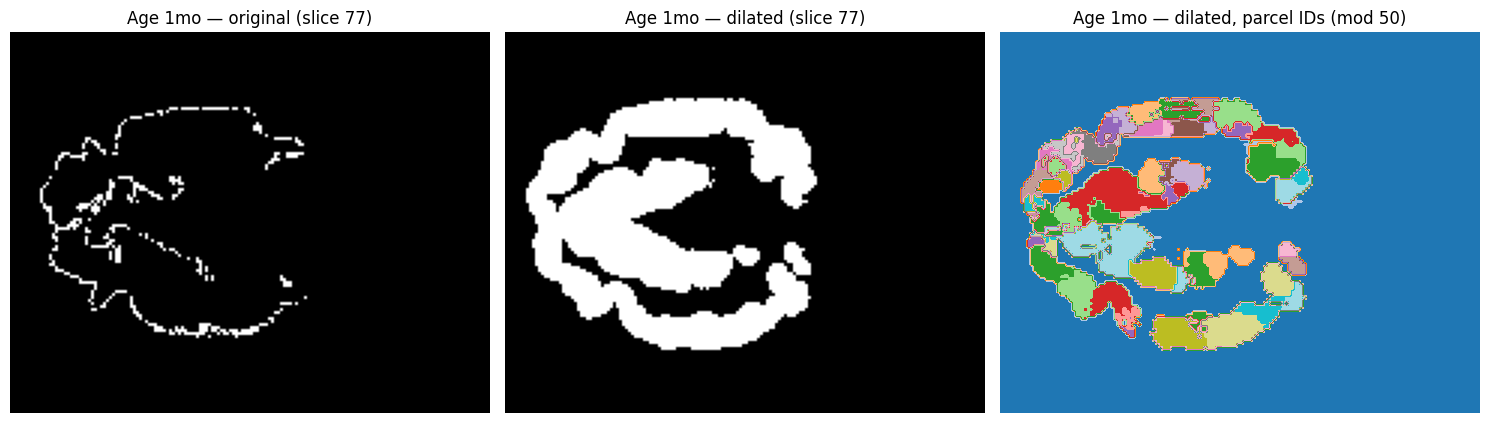

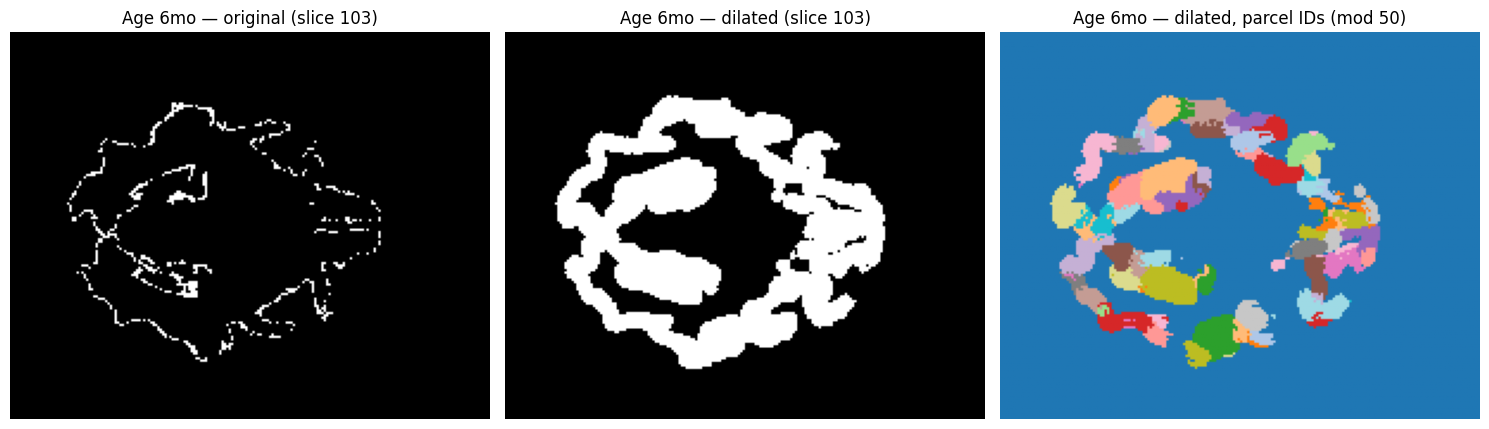

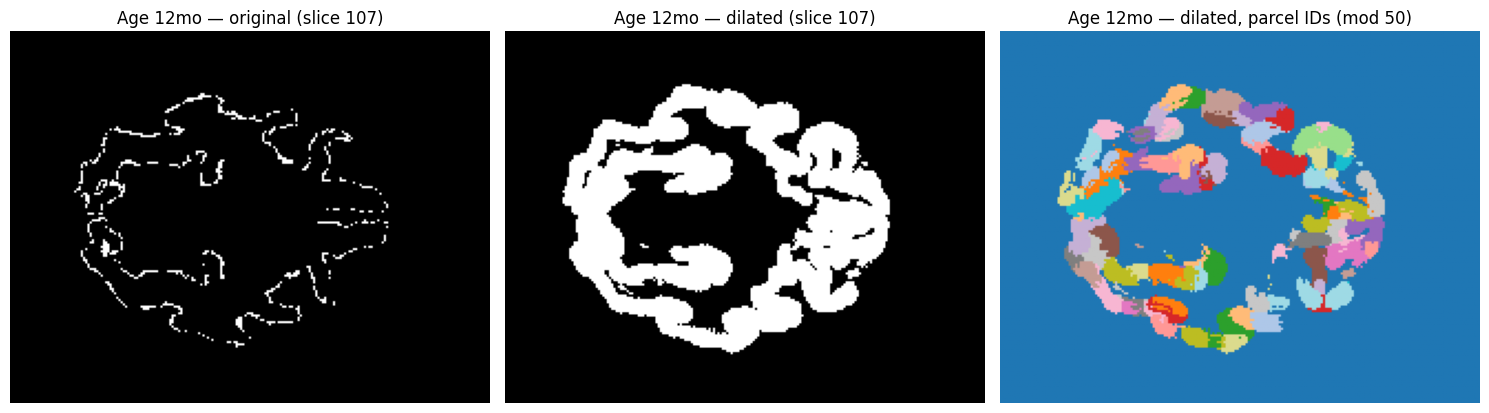

In [20]:
import matplotlib.pyplot as plt

for age, dilated in dilated_volumes.items():
    z_mid = dilated.shape[2] // 2
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original (pre-dilation) — re-load lightly
    parcellation, _, _ = load_wang432_atlas(ATLAS_FILES[age])
    
    axes[0].imshow((parcellation[:, :, z_mid] > 0), cmap='gray')
    axes[0].set_title(f'Age {age}mo — original (slice {z_mid})')
    axes[0].axis('off')
    
    axes[1].imshow((dilated[:, :, z_mid] > 0), cmap='gray')
    axes[1].set_title(f'Age {age}mo — dilated (slice {z_mid})')
    axes[1].axis('off')
    
    # Coloured by parcel ID for the dilated version (modulo to spread colours)
    axes[2].imshow(dilated[:, :, z_mid] % 50, cmap='tab20')
    axes[2].set_title(f'Age {age}mo — dilated, parcel IDs (mod 50)')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

## 5. Alignment check against data parcel IDs



In [21]:
def check_parcel_alignment(parcel_order, metadataDf, age=None, verbose=True):
    """Compare parcel IDs in the adjacency vs in the metadata."""
    if age is not None and 'Age' in metadataDf.columns:
        data_parcels = set(metadataDf.loc[metadataDf['Age'] == age, 'Parcel'].unique())
    else:
        data_parcels = set(metadataDf['Parcel'].unique())
    
    adj_parcels = set(parcel_order)
    matched = adj_parcels & data_parcels
    only_in_adjacency = adj_parcels - data_parcels
    only_in_data = data_parcels - adj_parcels
    
    if verbose:
        header = f"Age {age}mo" if age is not None else "All ages"
        print(f"\n=== Parcel alignment: {header} ===")
        print(f"  Parcels in adjacency: {len(adj_parcels)}")
        print(f"  Parcels in data:      {len(data_parcels)}")
        print(f"  Matched:              {len(matched)}")
        print(f"  Only in adjacency:    {len(only_in_adjacency)} (expected — atlas parcels outside FOV)")
        print(f"  Only in data:         {len(only_in_data)} (these will silently fail to get TFCE adjacency!)")
        
        if only_in_data:
            print(f"\n  WARNING — data parcels missing from adjacency:")
            for p in sorted(only_in_data)[:20]:
                print(f"    parcel ID {p}")
            if len(only_in_data) > 20:
                print(f"    ... and {len(only_in_data) - 20} more")
        
        if len(only_in_data) == 0:
            print(f"\n  ✓ Every data parcel is present in the adjacency.")
    
    return {
        'matched': matched,
        'only_in_adjacency': only_in_adjacency,
        'only_in_data': only_in_data,
    }

In [22]:
# Load metadata and run alignment checks
if METADATA_PATH is not None and Path(METADATA_PATH).exists():
    metadataDf = pd.read_csv(METADATA_PATH)
    print(f"Loaded metadata: {len(metadataDf):,} rows")
    print(f"Columns: {list(metadataDf.columns)}")
    
    if 'Age' in metadataDf.columns:
        print(f"Ages in data: {sorted(metadataDf['Age'].unique())}")
    
    for age, (adj, order) in adjacencies.items():
        check_parcel_alignment(order, metadataDf, age=age)
else:
    print("METADATA_PATH not set or file missing — skipping alignment check.")

Loaded metadata: 6,919,837 rows
Columns: ['Infant', 'Age', 'Run', 'Chrom', 'Parcel', 'Trial', 'Cap name', 'tsIDx']
Ages in data: [1, 6, 12]

=== Parcel alignment: Age 1mo ===
  Parcels in adjacency: 860
  Parcels in data:      617
  Matched:              617
  Only in adjacency:    243 (expected — atlas parcels outside FOV)
  Only in data:         0 (these will silently fail to get TFCE adjacency!)

  ✓ Every data parcel is present in the adjacency.

=== Parcel alignment: Age 6mo ===
  Parcels in adjacency: 860
  Parcels in data:      392
  Matched:              392
  Only in adjacency:    468 (expected — atlas parcels outside FOV)
  Only in data:         0 (these will silently fail to get TFCE adjacency!)

  ✓ Every data parcel is present in the adjacency.

=== Parcel alignment: Age 12mo ===
  Parcels in adjacency: 860
  Parcels in data:      337
  Matched:              337
  Only in adjacency:    523 (expected — atlas parcels outside FOV)
  Only in data:         0 (these will silentl

## 6. Save adjacency matrices to disk

Saves both per-age pickles (one file per age, easier to inspect individually) and a single combined pickle for convenience when loading in the TFCE pipeline.

The saved bundle records the source atlas paths and the parameters used to build the adjacency, so the artifact is self-documenting.

In [25]:
# Per-age pickles
for age, (adj, order) in adjacencies.items():
    out_path = OUTPUT_DIR / f"surfAdjacencyAge{age}mo.pkl"
    with open(out_path, 'wb') as f:
        pickle.dump({
            'adjacency': adj,
            'parcel_order': order,
            'source_atlas': str(ATLAS_FILES[age]),
            'voxel_size_mm': voxel_sizes.get(age),
            'dilation_radius_voxels': DILATION_RADIUS_VOXELS,
            'min_contact_voxels': MIN_CONTACT_VOXELS,
            'adjacency_connectivity': ADJACENCY_CONNECTIVITY,
            'lh_id_range': (LH_ID_MIN, LH_ID_MAX),
            'rh_id_range': (RH_ID_MIN, RH_ID_MAX),
        }, f)
    print(f"Saved {out_path} ({adj.shape[0]} parcels, {adj.sum() // 2} edges)")

# Combined pickle for easy loading in the TFCE pipeline
combined_path = OUTPUT_DIR / "surfAdjacenciesAllAges.pkl"
with open(combined_path, 'wb') as f:
    pickle.dump({
        age: {
            'adjacency': adj,
            'parcel_order': order,
        }
        for age, (adj, order) in adjacencies.items()
    }, f)
print(f"\nSaved combined: {combined_path}")

Saved /Volumes/Extreme SSD/mri/adjacencyMatrices/surfAdjacencyAge1mo.pkl (860 parcels, 2769 edges)
Saved /Volumes/Extreme SSD/mri/adjacencyMatrices/surfAdjacencyAge6mo.pkl (860 parcels, 2693 edges)
Saved /Volumes/Extreme SSD/mri/adjacencyMatrices/surfAdjacencyAge12mo.pkl (860 parcels, 2693 edges)

Saved combined: /Volumes/Extreme SSD/mri/adjacencyMatrices/surfAdjacenciesAllAges.pkl
